In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

In [8]:
# Read in text files with the filenames and labels 
def read_txt_files(path):

    rows = []

    with open(path, encoding='UTF-8') as f:
        
        for line in f:

            line = line.strip()

            filename = line.split(",")[0]

            labels = line.split(",")[1:]

            rows.append({'filename':filename, 'labels':labels})

        data = pd.DataFrame(rows)

        return data

test_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/test-set-v1.1.0.txt')

train_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/train-set-v1.1.0.txt')

val_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/val-set-v1.1.0.txt')

In [9]:
# Around 30 rows in the train data are not in the images so will drop these rows doesnt seem to be the same in val and test data so will leave as is there
image_dir = Path('rover_image_classification/mer-labeled-data-set-v1.1.0/images')

folder_files = []
for f in image_dir.iterdir():

    folder_files.append(f.name)

folder_files = pd.DataFrame(folder_files,columns=['filename'])

In [10]:
drop_train_data = train_data[~train_data['filename'].isin(folder_files['filename'])].index

train_data.drop(drop_train_data,inplace=True)

In [11]:
# No missing files in these datasets
print(len(val_data[~val_data['filename'].isin(folder_files['filename'])]))
print(len(test_data[~test_data['filename'].isin(folder_files['filename'])]))

0
0


In [12]:
# Filtering the data to only contain the original images of the dataset
orig_train_data = train_data[train_data['filename'].str.endswith('img.jpg')].copy()
orig_test_data = test_data[test_data['filename'].str.endswith('img.jpg')].copy()
orig_val_data = val_data[val_data['filename'].str.endswith('img.jpg')].copy()

In [13]:
# Loading images and returning arrays of the image data on the original pictures
def load_images(path):

    image = Image.open(image_dir/path)

    return np.array(image)

orig_train_data['images'] = orig_train_data['filename'].apply(load_images)
orig_test_data['images'] = orig_test_data['filename'].apply(load_images)
orig_val_data['images'] = orig_val_data['filename'].apply(load_images)

In [14]:
# Concatenating all data into one df to perform analysis on all data
data = pd.concat([orig_train_data, orig_val_data, orig_test_data], ignore_index=True)

LABEL 

In [15]:
data['labels'].unique

<bound method Series.unique of 0              [ Soil,  Spherules,  Sky,  Nearby Surface]
1       [ Rover Deck,  Dunes/Ripples,  Soil,  Spherule...
2       [ Rocks (misc),  Dunes/Ripples,  Soil,  Spheru...
3                    [ Soil,  Spherules,  Nearby Surface]
4       [ Rock Outcrops,  Clasts,  Rock (Linear Featur...
                              ...                        
2999    [ Float Rocks,  Clasts,  Dunes/Ripples,  Soil,...
3000    [ Rover Tracks,  Soil Trench,  Clasts,  Bright...
3001      [ Float Rocks,  Clasts,  Soil,  Nearby Surface]
3002    [ Rock Outcrops,  Clasts,  Dunes/Ripples,  Soi...
3003    [ Rock Outcrops,  Clasts,  Dunes/Ripples,  Roc...
Name: labels, Length: 3004, dtype: object>

In [16]:
data.head()

,filename,labels,images
0,1p128287181mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Sky, Nearby Surface]","[[121, 139, 143, 137, 141, 140, 134, 133, 140,..."
1,1p128287268mrd0000p2303l2m1.img.jpg,"[ Rover Deck, Dunes/Ripples, Soil, Spherule...","[[62, 54, 48, 51, 59, 61, 54, 45, 45, 52, 60, ..."
2,1p128288415mrd0000p2303l2m1.img.jpg,"[ Rocks (misc), Dunes/Ripples, Soil, Spheru...","[[116, 135, 139, 133, 135, 134, 129, 129, 137,..."
3,1p128289213mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Nearby Surface]","[[68, 55, 106, 97, 112, 123, 107, 106, 110, 10..."
4,1p129341281mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Clasts, Rock (Linear Featur...","[[108, 125, 141, 147, 149, 147, 135, 120, 133,..."


In [18]:
print(data["labels"].iloc[0])
print(type(data["labels"].iloc[0]))

[' Soil', ' Spherules', ' Sky', ' Nearby Surface']
<class 'list'>


In [22]:
label = data['labels'].explode()
labelcounter = label.value_counts()
print(labelcounter)


labels
Soil                         2891
Nearby Surface               2007
Rock Outcrops                1915
Clasts                       1676
Dunes/Ripples                1000
Sky                           955
Rock (Linear Features)        943
Distant Vista                 907
Spherules                     869
Float Rocks                   860
Rover Tracks                  301
Rover Parts                   301
Rocks (misc)                  249
Rover Deck                    222
Rock (Round Features)         219
Bright Soil                   122
Other Hardware                116
Soil Trench                    34
RAT Hole                       30
Artifacts                      28
Close-up Rock                  23
RAT Brushed Target             17
Pancam Calibration Target      14
Astronomy                      12
Arm Hardware                    4
Name: count, dtype: int64


<Axes: ylabel='labels'>

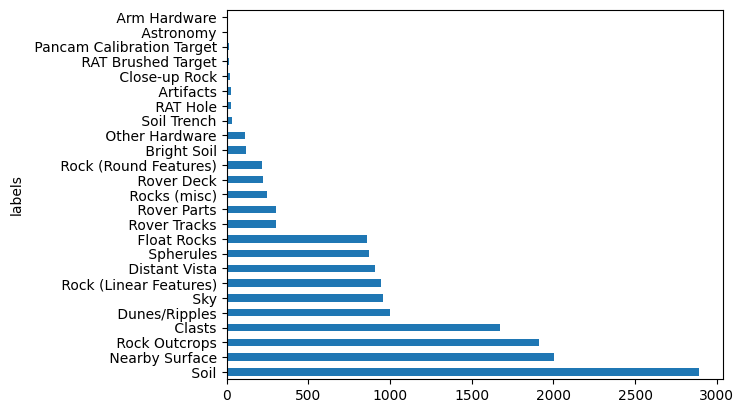

In [24]:
data['labels'].explode().value_counts().plot(kind='barh')

In [27]:
data['labelcounter'] = data['labels'].apply(len)
data['labelcounter'].describe()

count    3004.000000
mean        5.231358
std         1.309334
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        11.000000
Name: labelcounter, dtype: float64

<Axes: ylabel='labels'>

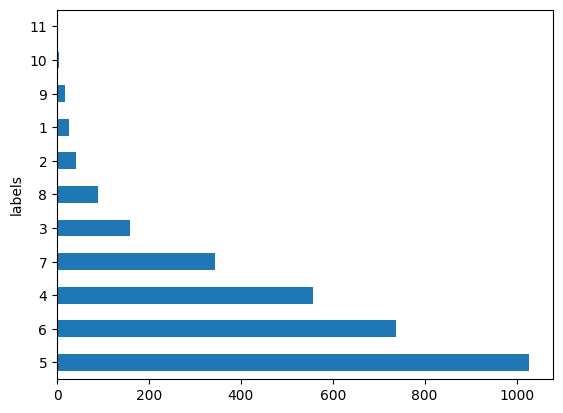

In [32]:
data['labels'].apply(len).value_counts().plot(kind='barh')